In [2]:
import warnings

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder ,StandardScaler,PowerTransformer
from sklearn.neighbors import KNeighborsClassifier


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


In [4]:
df=pd.read_csv('/content/IPL_processed_EDA.csv')

df.head()

,season,team1_runs,team1_wickets,overs_limit,match_month,match_day_of_week,is_chasing,toss_winner_is_team1,city_Abu Dhabi,city_Ahmedabad,...,toss_winner_Rising Pune Supergiants,toss_winner_Royal Challengers Bangalore,toss_winner_Royal Challengers Bengaluru,toss_winner_Sunrisers Hyderabad,toss_decision_bat,toss_decision_field,result_type_complete,result_type_no result,result_type_tie,team1_wins
0,-0.249389,0.208469,-0.836055,0.0,0.248872,-0.084330,0.701778,1.309903,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0
1,-0.786181,0.152261,-0.398730,0.0,0.699243,1.606471,-1.424952,1.309903,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1
2,-0.786181,0.548059,-0.836055,0.0,0.248872,-0.084330,-1.424952,1.309903,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1
3,0.292850,0.236616,0.462540,0.0,0.248872,-0.084330,0.701778,-0.763415,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0
4,-0.963909,-1.186055,1.309881,0.0,0.248872,-0.084330,0.701778,1.309903,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0


In [5]:
x = df.drop(columns=['team1_wins'])
y=df['team1_wins']

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

print('Training Shape:',x_train.shape)
print('Testing Shape:',x_test.shape)

Training Shape: (994, 168)
Testing Shape: (249, 168)


# KNN Model Training

In [11]:
knn = KNeighborsClassifier()

print('Training KNN model')
knn.fit(x_train,y_train)
print('Model Training complete')
print('no. of training samples:',knn.n_samples_fit_)

print('\nClasses:')
print(knn.classes_)
print("Stored X values:")
print(knn._fit_X[:5],"\n")
print("\n Stored Labels (first 5):")
print(knn._y[:5],"\n")

Training KNN model
Model Training complete
no. of training samples: 994

Classes:
[0 1]
Stored X values:
[[-0.24938949  0.46279142 -0.39872987  0.          0.6992432  -2.02050629
   0.70177809 -0.76341506  0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          1.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   1.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.

In [31]:
distances,indices = knn.kneighbors(x_test) # gives distance and index


print("Distance:")
print(distances)

print("Indices of nearest neighbors:")
print(indices)

d = pd.DataFrame(
    list(distances),
    columns=["Distance1", "Distance2", "Distance3", "Distance4", "Distance5"]
)
d['indices']=list(indices)

d.shape

Distance:
[[2.45990755 2.49334281 2.53345246 2.54952049 2.55422648]
 [2.18552521 2.8469784  2.85187129 2.85899484 3.07680722]
 [2.11101637 3.05550599 3.08077487 3.31243366 3.31553286]
 ...
 [2.71255806 3.19421186 3.29672243 3.31237523 3.3401382 ]
 [2.42509008 2.50910552 2.56610483 2.6597354  2.68782073]
 [2.66293717 2.73042714 2.75228098 2.75686581 2.84417083]]
Indices of nearest neighbors:
[[377 816 492  44 793]
 [956 435 416 942 140]
 [275 409 137  34 647]
 ...
 [542  23 524 135 550]
 [988 657 820 522 602]
 [649 799 615 698  84]]


(249, 6)

In [30]:
test_sample = x_test.iloc[0].values.reshape(1,-1)

distances,indices = knn.kneighbors(test_sample)

print("Test Sample:\n",test_sample)
print("\n Nearest Neighbors:\n")

for i in range(len(indices[0])):
  idx = indices[0][i]
  print(f"Neighbors {i+1}")
  print("Index : ",idx)
  print("Distance :",distances[0][i])
  print("Feature :\n",x_train.iloc[idx])
  print("Class :",y_train.iloc[i])
  print("-"*40)


Test Sample:
 [[ 0.47481478 -0.97305939  0.46253956  0.          0.24887152 -0.0843296
   0.70177809 -0.76341506  1.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.  

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


In [32]:
test_sample


array([[ 0.47481478, -0.97305939,  0.46253956,  0.        ,  0.24887152,
        -0.0843296 ,  0.70177809, -0.76341506,  1.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0. 

In [33]:
from collections import Counter


neighbor_classes = y_train.iloc[indices[0]]

print('Neighbor Classes:\n',neighbor_classes)

votes=Counter(neighbor_classes)
print(votes)

prediction = knn.predict(test_sample)

print("\n Final Prediction:",prediction[0])



Neighbor Classes:
 1004    1
150     0
506     0
797     0
80      0
Name: team1_wins, dtype: int64
Counter({0: 4, 1: 1})

 Final Prediction: 0


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


In [34]:
y_test_pred = knn.predict(x_test)

comparison = pd.DataFrame({
    "Actual":y_test.values,
    "Predicted":y_test_pred
})
print(comparison)

     Actual  Predicted
0         0          0
1         1          1
2         0          0
3         1          1
4         1          0
..      ...        ...
244       0          0
245       0          0
246       1          1
247       1          1
248       0          0

[249 rows x 2 columns]


/tmp/ipykernel_356/3951747866.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_test,ax=axes[0],palette="viridis")
/tmp/ipykernel_356/3951747866.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_test_pred,ax=axes[1],palette="plasma")


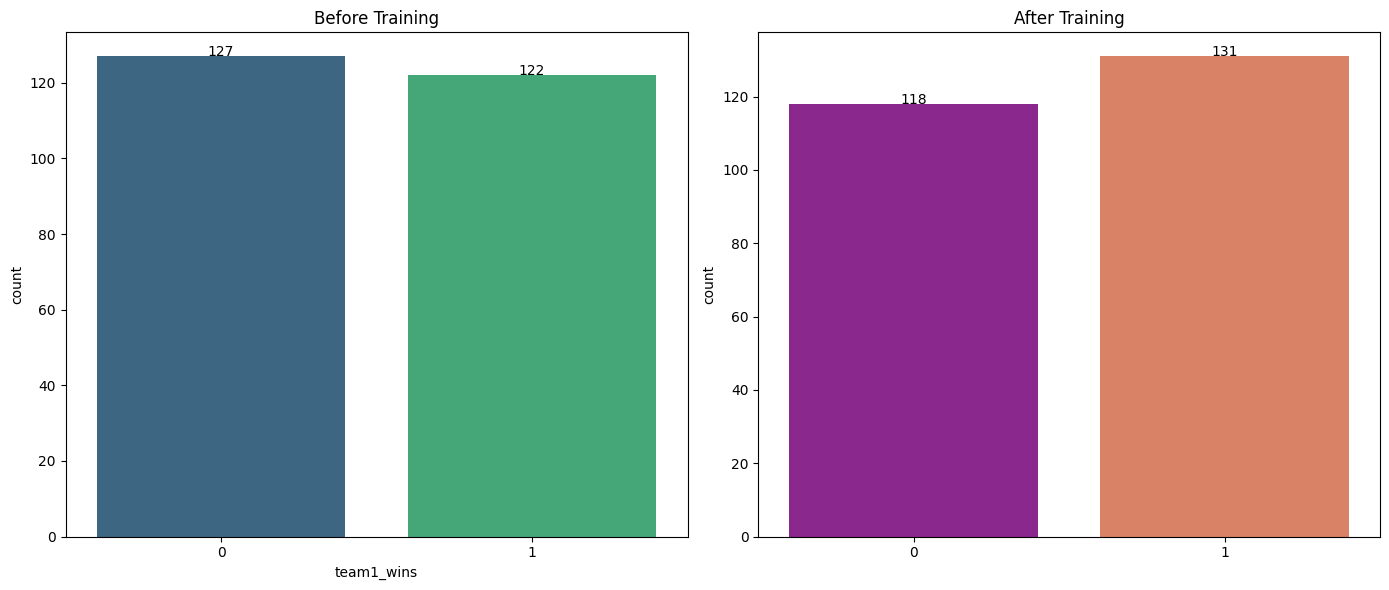

In [36]:
fig ,axes = plt.subplots(1,2,figsize=(14,6))

sns.countplot(x=y_test,ax=axes[0],palette="viridis")
axes[0].set_title("Before Training")

for bar in axes[0].patches:
  axes[0].text(
      bar.get_x()+bar.get_width()/2,
      bar.get_height(),
      int(bar.get_height()),
      ha='center'
  )


sns.countplot(x=y_test_pred,ax=axes[1],palette="plasma")
axes[1].set_title("After Training")

for bar in axes[1].patches:
  axes[1].text(
      bar.get_x()+bar.get_width()/2,
      bar.get_height(),
      int(bar.get_height()),
      ha='center'
  )

plt.tight_layout()
plt.show()


In [48]:
# Model Evaluation

y_pred = knn.predict(x_test)

cm = confusion_matrix(y_test,y_pred)

tn,fp,fn,tp =cm.ravel()
print("Confusion Matrix\n")

print("                        Positive  Negetive")
print(f"Predicted Positive      TP={tp:3d}    FP={fp:3d}")
print(f"Predicted Negative      FN={fn:3d}    TN={tn:3d}")
print("\n")
print(f"Accuracy Score :{accuracy_score(y_test,y_pred):.4f}")
print(f"Precision Score :{precision_score(y_test,y_pred):.4f}")
print(f"Recall Score :{recall_score(y_test,y_pred):.4f}")
print(f"F1 Score :{f1_score(y_test,y_pred):.4f}")

print("\n")

print("Classification Report:\n")
print(classification_report(y_test,y_pred))

Confusion Matrix

                        Positive  Negetive
Predicted Positive      TP= 83    FP= 48
Predicted Negative      FN= 39    TN= 79


Accuracy Score :0.6506
Precision Score :0.6336
Recall Score :0.6803
F1 Score :0.6561


Classification Report:

              precision    recall  f1-score   support

           0       0.67      0.62      0.64       127
           1       0.63      0.68      0.66       122

    accuracy                           0.65       249
   macro avg       0.65      0.65      0.65       249
weighted avg       0.65      0.65      0.65       249

